# When to Decide

*The Mathematics of Machine Intelligence · Chapter 15*

Weigh the price of waiting, the price of each error and the rarity of the event before you say yes.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask for the prior (how common the event is where the test is used), the hit and false-alarm rates for that population, the cost of each kind of error and the price of waiting. Then choose the matching card: Bayes' rule for what a positive report means, the cost cutoff for where to draw the line, a lead rule or a bound for how long to keep collecting evidence, the reward rate for how the price of time moves the bound. Report the answer, the assumption it depends on, and who supplied the costs.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 15, When to Decide: executable mathematics and reader-facing teaching content."""
import functools
import math
from math import comb
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'
HIT_RATE = 0.792
EDDY_FALSE_ALARM = 0.096

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def pct(value, digits=3):
    return sig(100 * value, digits) + ' percent'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 11)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def phi(x):
    """Standard normal cumulative distribution function."""
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def phi_inverse(p):
    """Inverse of phi by bisection (numpy only, no scipy)."""
    if not 0 < p < 1:
        raise ValueError('A probability strictly between 0 and 1 is needed.')
    lo, hi = (-12.0, 12.0)
    for _ in range(200):
        mid = (lo + hi) / 2
        if phi(mid) < p:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2

def positive_predictive_value(prior, hit_rate, false_alarm_rate):
    """P(condition | positive) = H pi / (H pi + F (1 - pi))."""
    if not (0 <= prior <= 1 and 0 <= hit_rate <= 1 and (0 <= false_alarm_rate <= 1)):
        raise ValueError('Probabilities must lie between 0 and 1.')
    flagged = hit_rate * prior + false_alarm_rate * (1 - prior)
    if flagged == 0:
        return None
    return hit_rate * prior / flagged

def bayes_picture(prior=0.01, false_alarm=0.096):
    ppv = positive_predictive_value(prior, HIT_RATE, false_alarm)
    sick = 1000 * prior
    healthy = 1000 - sick
    real = HIT_RATE * sick
    false_flags = false_alarm * healthy
    fig, ax = panels()
    bars = ax[0].bar(['have it,\nflagged', 'healthy,\nflagged'], [real, false_flags], color=[TEAL, TERRA], width=0.55)
    top = max(real, false_flags) * 1.25 + 1
    for bar, v in zip(bars, [real, false_flags]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + top * 0.02, sig(v), va='bottom')
    ax[0].set(ylabel='women flagged, out of 1,000', title='Who raises the alarms?', ylim=(0, top))
    ax[0].text(0.5, 0.96, f'{sig(sick)} of 1,000 have it; the test finds {sig(100 * HIT_RATE)} percent', transform=ax[0].transAxes, ha='center', va='top', fontsize=9, color=GREY)
    grid = np.geomspace(0.0008, 0.4, 200)
    for other, style, colour in [(0.01, 'dotted', GREY), (0.05, 'dashed', GOLD), (0.096, 'solid', TEAL), (0.2, 'dashed', TERRA)]:
        chosen = abs(other - false_alarm) < 1e-12
        curve = [positive_predictive_value(g, HIT_RATE, other) for g in grid]
        ax[1].plot(grid, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'false-alarm rate {other:g}')
    ring(ax[1], prior, ppv)
    ax[1].set_xscale('log')
    ax[1].set_xticks([0.001, 0.01, 0.1])
    ax[1].set_xticklabels(['0.001', '0.01', '0.1'])
    ax[1].set(xlabel='prior: chance before testing', ylabel='share of positive reports that are real', title='Rarity decides what a positive means', ylim=(0, 1.02), xlim=(0.0008, 0.4))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    metrics = {'Real alarms per 1,000': sig(real), 'False alarms per 1,000': sig(false_flags), 'Share of alarms that are real': pct(ppv), 'Test finds': pct(HIT_RATE)}
    summary = f'Of 1,000 women with a prior of {sig(prior)}, about {sig(real)} real cases and {sig(false_flags)} healthy women are flagged. So {pct(ppv)} of positive reports are real, though the test finds {sig(100 * HIT_RATE)} percent of cases.'
    calc = f'Numerator H x prior = {HIT_RATE:g} x {prior:g} = {sig(HIT_RATE * prior)}. False-positive part F x (1 - prior) = {false_alarm:g} x {sig(1 - prior)} = {sig(false_alarm * (1 - prior))}. Share = {sig(HIT_RATE * prior)} / ({sig(HIT_RATE * prior)} + {sig(false_alarm * (1 - prior))}) = {sig(ppv)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def detection_rates(dprime, cutoff):
    """Equal-width normal heaps: no-flash heap centred at 0, flash heap at d-prime, cutoff in sd units."""
    return {'hit': phi(dprime - cutoff), 'false_alarm': phi(-cutoff)}

def eddy_dprime():
    """The d-prime that Eddy's two rates imply under the equal-width normal model (the companion's reading)."""
    return phi_inverse(HIT_RATE) - phi_inverse(EDDY_FALSE_ALARM)

def normal_pdf(x, mean=0.0):
    return np.exp(-0.5 * (x - mean) ** 2) / math.sqrt(2 * math.pi)

def detection_picture(dprime=2.12, cutoff=1.3):
    rates = detection_rates(dprime, cutoff)
    hit, fa = (rates['hit'], rates['false_alarm'])
    ppv = positive_predictive_value(0.01, hit, fa)
    fig, ax = panels()
    x = np.linspace(-3.5, dprime + 3.5, 600)
    ax[0].plot(x, normal_pdf(x), color=TERRA, linewidth=2, label='no flash')
    ax[0].plot(x, normal_pdf(x, dprime), color=TEAL, linewidth=2, label='flash')
    right = x >= cutoff
    ax[0].fill_between(x[right], normal_pdf(x[right]), color=TERRA, alpha=0.35)
    ax[0].fill_between(x[right], normal_pdf(x[right], dprime), color=TEAL, alpha=0.2)
    ax[0].axvline(cutoff, color=NAVY, linewidth=2, linestyle='dashed')
    ax[0].set(xlabel='strength of evidence (no-flash spread = 1)', ylabel='how often each strength turns up', title='Shaded beyond the cutoff means yes', ylim=(0, 0.52))
    tag(ax[0], cutoff, 0.5, 'cutoff', va='top', color=NAVY, fontsize=10)
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    grid_fa = np.linspace(0.001, 0.999, 400)
    for other, style, colour in [(0.5, 'dotted', GREY), (1.0, 'dashed', GOLD), (2.12, 'solid', TEAL), (3.0, 'dashed', TERRA)]:
        chosen = abs(other - dprime) < 1e-12
        curve = [phi(other + phi_inverse(f)) for f in grid_fa]
        ax[1].plot(grid_fa, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'sharpness {other:g}')
    ax[1].plot([0, 1], [0, 1], color=GREY, linewidth=1, linestyle='dotted')
    ax[1].plot([EDDY_FALSE_ALARM], [HIT_RATE], marker='*', markersize=12, color=GOLD, markeredgecolor=DARK_GOLD, zorder=5)
    tag(ax[1], 0.12, 0.7, "Eddy's\n0.096, 0.792", fontsize=9, ha='left', va='top', color=DARK_GOLD)
    ring(ax[1], fa, hit)
    ax[1].set(xlabel='false-alarm rate', ylabel='hit rate', title='Same evidence, different cutoffs', xlim=(0, 1), ylim=(0, 1.02))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    metrics = {'Hit rate': pct(hit), 'False-alarm rate': pct(fa), 'Real share of alarms at prior 0.01': pct(ppv), 'Sharpness (d-prime)': sig(dprime)}
    summary = f'With sharpness {sig(dprime)} and the cutoff {sig(cutoff)} spreads above the no-flash centre, the hit rate is {pct(hit)} and the false-alarm rate {pct(fa)}. Move the cutoff and both rates move together; only a different sharpness changes the curve itself.'
    calc = f"Hit = Phi(d' - c) = Phi({sig(dprime)} - {sig(cutoff)}) = {sig(hit)}. False alarm = Phi(-c) = Phi({sig(-cutoff)}) = {sig(fa)}. At a prior of 0.01 the real share of alarms is {sig(hit)} x 0.01 / ({sig(hit)} x 0.01 + {sig(fa)} x 0.99) = {sig(ppv)}. Sharpness 2.12 is the companion's reading of Eddy's two rates under equal-width normal heaps; the other sharpness values are constructed."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def cutoff_from_costs(miss_cost, false_alarm_cost=1.0):
    """Say yes when the chance of the case exceeds C_fa / (C_fa + C_miss); costs must be positive."""
    if not (miss_cost > 0 and false_alarm_cost > 0):
        raise ValueError('Both costs must be above zero.')
    return false_alarm_cost / (false_alarm_cost + miss_cost)

def expected_costs(p, miss_cost, false_alarm_cost=1.0):
    """Expected cost of saying yes (a false alarm if healthy) and of saying no (a miss if the case is real)."""
    return {'yes': (1 - p) * false_alarm_cost, 'no': p * miss_cost}

def cost_picture(cost_ratio=9, p=0.1):
    t = cutoff_from_costs(cost_ratio)
    costs = expected_costs(p, cost_ratio)
    fig, ax = panels()
    grid = np.linspace(0, 0.55, 400)
    ax[0].plot(grid, 1 - grid, color=TERRA, linewidth=2.5, label='say yes')
    ax[0].plot(grid, np.minimum(grid * cost_ratio, 5), color=TEAL, linewidth=2.5, label='say no')
    ax[0].axvline(t, color=NAVY, linewidth=1.5, linestyle='dashed')
    tag(ax[0], t + 0.01, 0.12, f'cutoff {sig(t)}', fontsize=9, color=NAVY, ha='left')
    ring(ax[0], p, costs['yes'])
    ring(ax[0], p, min(costs['no'], 1.03))
    ax[0].set(xlabel='chance the case is real', ylabel='expected cost (a false alarm costs 1)', title='Cheaper action at each chance', ylim=(0, 1.05), xlim=(0, 0.55))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    ratios = np.geomspace(1, 100, 200)
    ax[1].plot(ratios, [cutoff_from_costs(r) for r in ratios], color=TEAL, linewidth=2.5)
    ring(ax[1], cost_ratio, t)
    ax[1].set_xscale('log')
    ax[1].set_xticks([1, 2, 5, 10, 20, 50, 100])
    ax[1].set_xticklabels(['1', '2', '5', '10', '20', '50', '100'])
    ax[1].set(xlabel='cost of a miss / cost of a false alarm', ylabel='say yes above this chance', title='Dearer misses lower the cutoff', ylim=(0, 0.55))
    tag(ax[1], 90, 0.5, 'Always saying no at\n1 case in 100: 99 percent\nright, finds no one', fontsize=9, ha='right', va='top', color=DARK_GOLD)
    if abs(costs['yes'] - costs['no']) < 1e-09:
        cheaper = 'equal cost (a tie)'
    else:
        cheaper = 'say yes' if costs['yes'] < costs['no'] else 'say no'
    metrics = {'Say yes above chance': sig(t), 'Cost of saying yes': sig(costs['yes']), 'Cost of saying no': sig(costs['no']), 'Cheaper action': cheaper}
    summary = f"With a miss costing {cost_ratio:g} times a false alarm, the cheapest rule says yes above a chance of {sig(t)}. At a chance of {sig(p)}, saying yes costs {sig(costs['yes'])} and saying no costs {sig(costs['no'])}, so the cheaper action is: {cheaper}."
    calc = f"Cutoff = 1/(1 + {cost_ratio:g}) = {sig(t)}. Saying yes costs (1 - {sig(p)}) x 1 = {sig(costs['yes'])}. Saying no costs {sig(p)} x {cost_ratio:g} = {sig(costs['no'])}. This assumes the stated chance is trustworthy and a correct call costs nothing."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def noise_free_time(drift, bound):
    return bound / drift

def diffusion_mean_time(drift, noise, bound):
    """Mean time to reach +-bound from 0 with drift v and noise sigma: (a/v) tanh(a v / sigma^2)."""
    if drift <= 0 or bound <= 0 or noise < 0:
        raise ValueError('Drift and bound must be above zero and noise cannot be negative.')
    if noise == 0:
        return bound / drift
    return bound / drift * math.tanh(bound * drift / noise ** 2)

def diffusion_error_rate(drift, noise, bound):
    """Chance of ending at the lower edge when the drift points up: 1/(1 + exp(2 a v / sigma^2))."""
    if noise == 0:
        return 0.0
    exponent = 2 * bound * drift / noise ** 2
    return 0.0 if exponent > 700 else 1 / (1 + math.exp(exponent))

def simulate_paths(drift, noise, bound, trials, seed, dt=0.01, max_time=40.0):
    """Euler steps of dX = v dt + sigma dW from 0 until |X| reaches the bound. Returns paths, stop times, edges."""
    rng = np.random.default_rng(seed)
    steps = int(max_time / dt)
    paths, times, edges = ([], [], [])
    for _ in range(trials):
        x, path = (0.0, [0.0])
        stop, edge = (None, 0)
        increments = rng.normal(0.0, 1.0, steps)
        for k in range(steps):
            x += drift * dt + noise * math.sqrt(dt) * increments[k]
            if abs(x) >= bound:
                x = math.copysign(bound, x)
                path.append(x)
                stop, edge = ((k + 1) * dt, 1 if x > 0 else -1)
                break
            path.append(x)
        paths.append(np.array(path))
        times.append(stop)
        edges.append(edge)
    return (paths, times, edges)

def diffusion_picture(drift=2, noise=4, bound=10):
    exact_time = diffusion_mean_time(drift, noise, bound)
    exact_error = diffusion_error_rate(drift, noise, bound)
    free = noise_free_time(drift, bound)
    paths, times, edges = simulate_paths(drift, noise, bound, 6, seed=15)
    fig, ax = panels()
    for path, edge in zip(paths, edges):
        t = np.arange(len(path)) * 0.01
        ax[0].plot(t, path, color=TEAL if edge >= 0 else TERRA, linewidth=1.3, alpha=0.9)
    longest = max((len(p) for p in paths)) * 0.01
    ax[0].plot([0, free], [0, bound], color=NAVY, linewidth=2.5, linestyle='dashed', label='average climb (no noise)')
    ax[0].axhline(bound, color=GREY, linewidth=1.2)
    ax[0].axhline(-bound, color=GREY, linewidth=1.2)
    ax[0].set(xlabel='time (seconds)', ylabel='evidence total', title='Six simulated trials (seed 15)', xlim=(0, max(longest, free) * 1.05), ylim=(-bound * 1.3, bound * 1.3))
    ax[0].text(0.98, 0.97, 'upper bound: right answer', transform=ax[0].transAxes, fontsize=9, color=GREY, va='top', ha='right')
    ax[0].text(0.98, 0.03, 'lower bound: wrong answer', transform=ax[0].transAxes, fontsize=9, color=GREY, va='bottom', ha='right')
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    grid = np.linspace(0.5, 5, 90)
    for other, style, colour in [(0, 'dotted', GREY), (2, 'solid', TEAL), (4, 'dashed', GOLD), (8, 'dashed', TERRA)]:
        chosen = other == noise
        curve = [diffusion_mean_time(g, other, bound) for g in grid]
        ax[1].plot(grid, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'noise {other:g}')
    ring(ax[1], drift, exact_time)
    ax[1].set_yscale('log')
    ax[1].set_yticks([0.25, 0.5, 1, 2, 5, 10, 20])
    ax[1].set_yticklabels(['0.25', '0.5', '1', '2', '5', '10', '20'])
    ax[1].set(xlabel='drift (evidence points per second)', ylabel='mean decision time (s, log scale)', title='Stronger drift, earlier finish', ylim=(0.2, 25))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4)
    stopped = [t for t in times if t is not None]
    upper = sum((1 for e in edges if e > 0))
    metrics = {'Time with no noise (s)': sig(free), 'Mean decision time with noise (s)': sig(exact_time), 'Chance of the wrong edge': pct(exact_error), 'Drawn trials that hit the upper edge': f'{upper} of 6'}
    spread = f'The six drawn trials stopped between {sig(min(stopped))} and {sig(max(stopped))} s.' if len(stopped) == 6 else 'Not every drawn trial stopped within 40 s.'
    summary = f'With drift {drift:g}, noise {noise:g} and bound {bound:g}, the noise-free climb takes {sig(free)} s. {spread} The exact mean over all trials is {sig(exact_time)} s, with a {pct(exact_error)} chance of ending at the wrong edge.'
    if noise == 0:
        calc = f'No noise: time = bound / drift = {bound:g}/{drift:g} = {sig(free)} s, and the lower edge is never reached (error 0).'
    else:
        calc = f'Noise-free time = a/v = {bound:g}/{drift:g} = {sig(free)} s. Mean time with noise = (a/v) tanh(a v / sigma^2) = {sig(free)} x tanh({bound:g} x {drift:g} / {noise:g}^2) = {sig(exact_time)} s. Chance of the wrong edge = 1/(1 + exp(2 a v / sigma^2)) = {sig(exact_error)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def fixed_vote_accuracy(q, n):
    """Chance that a majority of n (odd) independent votes, each right with chance q, is right."""
    if n % 2 == 0 or n < 1:
        raise ValueError('Use an odd number of votes.')
    return sum((comb(n, k) * q ** k * (1 - q) ** (n - k) for k in range((n + 1) // 2, n + 1)))

def lead_rule_stats(q, lead):
    """Stop when one answer is `lead` votes ahead. Returns chance of ending right and mean votes."""
    if lead < 1:
        raise ValueError('The lead must be at least one vote.')
    if abs(q - 0.5) < 1e-12:
        return {'accuracy': 0.5, 'votes': float(lead * lead)}
    accuracy = 1 / (1 + ((1 - q) / q) ** lead)
    votes = lead * (2 * accuracy - 1) / (2 * q - 1)
    return {'accuracy': accuracy, 'votes': votes}

def matching_fixed_votes(q, target, limit=2001):
    """Smallest odd number of fixed votes whose accuracy reaches the target; None if above the limit."""
    n = 1
    while n <= limit:
        if fixed_vote_accuracy(q, n) >= target - 1e-12:
            return n
        n += 2
    return None

def lead_picture(accuracy=0.7, lead=3):
    stats = lead_rule_stats(accuracy, lead)
    fixed9 = fixed_vote_accuracy(accuracy, 9)
    match = matching_fixed_votes(accuracy, stats['accuracy'])
    fig, ax = panels()
    grid = np.linspace(0.505, 0.95, 120)
    others = [(2, 'dotted', GREY), (3, 'dashed', TEAL), (5, 'dashed', TERRA)]
    ax[0].plot(grid, [fixed_vote_accuracy(g, 9) for g in grid], color=GOLD, linewidth=2.2, linestyle='dashed', label='always 9 votes')
    for other, style, colour in others:
        if other != lead:
            ax[0].plot(grid, [lead_rule_stats(g, other)['accuracy'] for g in grid], color=colour, linestyle=style, linewidth=1.5, label=f'stop at lead {other}')
    ax[0].plot(grid, [lead_rule_stats(g, lead)['accuracy'] for g in grid], color=NAVY, linewidth=3, label=f'stop at lead {lead} (chosen)')
    ring(ax[0], accuracy, stats['accuracy'])
    ax[0].set(xlabel='chance each vote is right', ylabel='chance the final answer is right', title='Accuracy of the two rules', ylim=(0.45, 1.02))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    ax[1].axhline(9, color=GOLD, linewidth=2.2, linestyle='dashed', label='always 9 votes')
    for other, style, colour in others:
        if other != lead:
            ax[1].plot(grid, [lead_rule_stats(g, other)['votes'] for g in grid], color=colour, linestyle=style, linewidth=1.5, label=f'stop at lead {other}')
    ax[1].plot(grid, [lead_rule_stats(g, lead)['votes'] for g in grid], color=NAVY, linewidth=3, label=f'stop at lead {lead} (chosen)')
    ring(ax[1], accuracy, stats['votes'])
    ax[1].set(xlabel='chance each vote is right', ylabel='average votes asked', title='Votes used on average', ylim=(0, 28))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    match_text = str(match) if match is not None else 'more than 2001'
    metrics = {'Lead rule: chance right': pct(stats['accuracy']), 'Always 9 votes: chance right': pct(fixed9), 'Lead rule: average votes': sig(stats['votes']), 'Fixed votes needed to match the lead rule': match_text}
    summary = f"Judges who are each right with chance {sig(accuracy)} give a lead-{lead} rule a {pct(stats['accuracy'])} chance of ending right, using {sig(stats['votes'])} votes on average. A fixed count needs {match_text} votes to reach that accuracy; always 9 gives {pct(fixed9)}."
    calc = f"Lead rule: chance right = 1/(1 + ((1 - q)/q)^L) = 1/(1 + ({sig(1 - accuracy)}/{sig(accuracy)})^{lead}) = {sig(stats['accuracy'])}. Average votes = L (2P - 1)/(2q - 1) = {lead} x {sig(2 * stats['accuracy'] - 1)} / {sig(2 * accuracy - 1)} = {sig(stats['votes'])}. Fixed 9: chance of at least 5 right votes = {sig(fixed9)}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
CAREFUL = {'decision_time': 1.2, 'error_rate': 0.05}
QUICK = {'decision_time': 0.6, 'error_rate': 0.15}
NON_DECISION = 0.3

def reward_rate(error_rate, decision_time, non_decision, delay, timeout):
    """RR = (1 - ER) / (DT + Tnd + D + ER x Dp), correct answers per second."""
    cycle = decision_time + non_decision + delay + error_rate * timeout
    if cycle <= 0:
        return None
    return (1 - error_rate) / cycle

def crossing_delay(timeout, a=CAREFUL, b=QUICK, non_decision=NON_DECISION):
    """Delay at which the two settings earn the same rate; None when it would be negative."""
    ea, eb = (a['error_rate'], b['error_rate'])
    ca = a['decision_time'] + non_decision + ea * timeout
    cb = b['decision_time'] + non_decision + eb * timeout
    delay = ((1 - eb) * ca - (1 - ea) * cb) / (eb - ea)
    return delay if delay >= 0 else None

def reward_picture(delay=2, timeout=0):
    rc = reward_rate(CAREFUL['error_rate'], CAREFUL['decision_time'], NON_DECISION, delay, timeout)
    rq = reward_rate(QUICK['error_rate'], QUICK['decision_time'], NON_DECISION, delay, timeout)
    cross = crossing_delay(timeout)
    fig, ax = panels()
    bars = ax[0].bar(['careful\n1.2 s, 5% errors', 'quick\n0.6 s, 15% errors'], [rc, rq], color=[TEAL, TERRA], width=0.55)
    top = max(rc, rq) * 1.3
    for bar, v in zip(bars, [rc, rq]):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + top * 0.02, sig(v), va='bottom')
    ax[0].set(ylabel='correct answers per second', title='Reward rate of each setting', ylim=(0, top))
    ax[0].tick_params(axis='x', labelsize=9)
    grid = np.linspace(0, 10, 200)
    ratio = [reward_rate(CAREFUL['error_rate'], CAREFUL['decision_time'], NON_DECISION, g, timeout) / reward_rate(QUICK['error_rate'], QUICK['decision_time'], NON_DECISION, g, timeout) for g in grid]
    ax[1].plot(grid, ratio, color=TEAL, linewidth=2.5)
    ax[1].axhline(1, color=GREY, linewidth=1.2, linestyle='dotted')
    ax[1].fill_between(grid, 1, ratio, where=np.array(ratio) >= 1, color=TEAL, alpha=0.2)
    ax[1].fill_between(grid, 1, ratio, where=np.array(ratio) < 1, color=TERRA, alpha=0.2)
    tag(ax[1], 9.8, 1.004, 'careful earns more', fontsize=9, color=TEAL, ha='right', va='bottom')
    tag(ax[1], 9.8, 0.58, 'quick earns more', fontsize=9, color=TERRA, ha='right', va='bottom')
    if cross is not None:
        ax[1].axvline(cross, color=GREY, linewidth=1.2, linestyle='dotted')
        tag(ax[1], cross + 0.2, 0.75, f'tie at\ndelay {sig(cross)} s', fontsize=9, color=GREY, va='top', ha='left')
    ring(ax[1], delay, rc / rq)
    ax[1].set(xlabel='delay between trials (seconds)', ylabel='careful rate / quick rate', title='The price of time picks the setting', ylim=(0.55, 1.12), xlim=(-0.4, 10.4))
    if abs(rc - rq) < 1e-09:
        better = 'tie'
    else:
        better = 'careful' if rc > rq else 'quick'
    cross_text = f'{sig(cross)} s' if cross is not None else 'none (one setting earns more at every delay)'
    metrics = {'Careful: correct per second': sig(rc), 'Quick: correct per second': sig(rq), 'Earns more': better, 'Delay where they tie': cross_text}
    summary = f'With a {delay:g} s delay between trials and a {timeout:g} s time-out after errors, careful earns {sig(rc)} correct answers a second and quick {sig(rq)}, so {better} earns more. The two settings tie at a delay of {cross_text}.'
    calc = f'Careful: (1 - 0.05) / (1.2 + 0.3 + {delay:g} + 0.05 x {timeout:g}) = {sig(rc)}. Quick: (1 - 0.15) / (0.6 + 0.3 + {delay:g} + 0.15 x {timeout:g}) = {sig(rq)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
CAP = 40

@functools.lru_cache(maxsize=None)
def settle_estimate(count_a, count_b):
    """Mass of Beta(a + 1, b + 1) above one half for the leader's count a >= b: P(Bin(a + b + 1, 1/2) <= a)."""
    lead, trail = (max(count_a, count_b), min(count_a, count_b))
    n = lead + trail + 1
    return sum((comb(n, k) for k in range(0, lead + 1))) / 2 ** n

@functools.lru_cache(maxsize=None)
def sampler_distribution_cached(share, threshold, cap):
    states = {(0, 0): 1.0}
    stop_a = np.zeros(cap + 1)
    stop_b = np.zeros(cap + 1)
    for n in range(1, cap + 1):
        new = {}
        for (a, b), mass in states.items():
            new[a + 1, b] = new.get((a + 1, b), 0.0) + mass * share
            new[a, b + 1] = new.get((a, b + 1), 0.0) + mass * (1 - share)
        states = {}
        for (a, b), mass in new.items():
            if mass == 0:
                continue
            if a != b and settle_estimate(a, b) > threshold:
                if a > b:
                    stop_a[n] += mass
                else:
                    stop_b[n] += mass
            else:
                states[a, b] = mass
    capped = sum(states.values())
    capped_a = sum((m for (a, b), m in states.items() if a > b))
    capped_b = sum((m for (a, b), m in states.items() if b > a))
    capped_tie = sum((m for (a, b), m in states.items() if a == b))
    mean = float(np.sum(np.arange(cap + 1) * (stop_a + stop_b)) + cap * capped)
    return {'mean': mean, 'stop_a': float(stop_a.sum()), 'stop_b': float(stop_b.sum()), 'capped': capped, 'capped_a': capped_a, 'capped_b': capped_b, 'capped_tie': capped_tie, 'pmf_a': stop_a, 'pmf_b': stop_b}

def sampler_distribution(share, threshold, cap=CAP):
    """Exact distribution for a two-answer tally. Each sample is answer A with chance `share` (A is the truly likelier one).

    Stops when the leader's settle estimate exceeds the threshold, or at the cap. Returns the mean number of
    samples, the chances of stopping on A, on B, of reaching the cap (split into A ahead, B ahead and tied),
    and the per-sample stop masses.
    """
    return sampler_distribution_cached(float(share), float(threshold), int(cap))

def earliest_stop(threshold):
    """Fewest samples at which an unbroken run of one answer clears the threshold."""
    n = 1
    while settle_estimate(n, 0) <= threshold:
        n += 1
    return n

def sampler_picture(share=0.8, threshold=0.95):
    data = sampler_distribution(share, threshold)
    fig, ax = panels()
    n = np.arange(CAP + 1)
    ax[0].bar(n, data['pmf_a'], color=TEAL, width=0.85, label='stops on the likelier answer')
    ax[0].bar(n, data['pmf_b'], bottom=data['pmf_a'], color=TERRA, width=0.85, label='stops on the runner-up')
    ax[0].set(xlabel='samples drawn when it stops', ylabel='chance of stopping here', title='When does the sampler stop?', xlim=(0, CAP + 1))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    if data['capped'] > 1e-09:
        tag(ax[0], 0.97, 0.62, f"{pct(data['capped'])} reach\nthe cap of {CAP}", transform=ax[0].transAxes, fontsize=9, ha='right', va='top', color=GREY)
    grid = [0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]
    for other, style, colour in [(0.9, 'dotted', GREY), (0.95, 'solid', TEAL), (0.99, 'dashed', TERRA)]:
        chosen = abs(other - threshold) < 1e-12
        ax[1].plot(grid, [sampler_distribution(g, other)['mean'] for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'stop above {other:g}')
    ax[1].axhline(CAP, color=GOLD, linewidth=1.8, linestyle='dashed')
    tag(ax[1], 0.8, CAP - 1.2, f'fixed budget of {CAP}', fontsize=9, color=DARK_GOLD, va='top')
    ring(ax[1], share, data['mean'])
    ax[1].set(xlabel='chance each sample gives the likelier answer', ylabel='average samples drawn', title='Close races cost more samples', ylim=(0, CAP + 3))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
    first = earliest_stop(threshold)
    wrong_total = data['stop_b'] + data['capped_b']
    metrics = {'Average samples drawn': sig(data['mean']), 'Chance it stops on the runner-up before the cap': pct(data['stop_b']), 'Chance it hits the cap': pct(data['capped']), 'Chance of a wrong final answer, cap included': pct(wrong_total)}
    summary = f"When {pct(share, 3)} of samples give the likelier answer and the sampler stops above {threshold:g}, it draws {sig(data['mean'])} samples on average against a fixed {CAP}. It stops on the runner-up {pct(data['stop_b'])} of the time, and the final answer is wrong {pct(wrong_total)} of the time if capped runs return their leader. Settled means stable, not true."
    calc = f"Estimate = P(Bin(a + b + 1, 1/2) <= a) for the leader's count a. Four unbroken matches give P(Bin(5, 1/2) <= 4) = 31/32 = 0.969. At threshold {threshold:g} the earliest stop is after {first} samples. The exact tally is a sum over all (a, b) counts, not a simulation. The estimate is the companion's reading of the chapter's description. Wrong if a capped run returns its leader = stops on the runner-up {pct(data['stop_b'])} + capped with the runner-up ahead {pct(data['capped_b'])} = {pct(wrong_total)}; {pct(data['capped_tie'])} of runs reach the cap tied and have no leader. That cap rule is the companion's assumption; the chapter suggests handing an unsettled case to a person."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C15-D01: Why are most positive reports false when the test finds four cancers in five?

If a test finds 79.2 percent of cancers and wrongly flags 9.6 percent of healthy cases, what share of its positive reports are real when the condition is rare?

Of 1,000 women, 10 have cancer and the test flags about 8 of them. Of the 990 without cancer it flags about 95. So about 103 reports are positive and 8 are real. The two chances were confused: the chance of a positive report given cancer (79.2 percent) is not the chance of cancer given a positive report. The right-hand curves show that the same test means very different things at different priors.

$$
P(\text{condition}\mid +)=\frac{H\pi}{H\pi+F(1-\pi)}
$$

**Symbols:** pi: the prior: the chance of the condition before any test result; H: the hit rate: chance of a positive report when the condition is present (0.792 here); F: the false-alarm rate: chance of a positive report when it is absent

**Predict before looking:** Before moving any slider, predict the share of positive reports that are real with the book's numbers, then predict what happens if 1 woman in 10 has cancer.

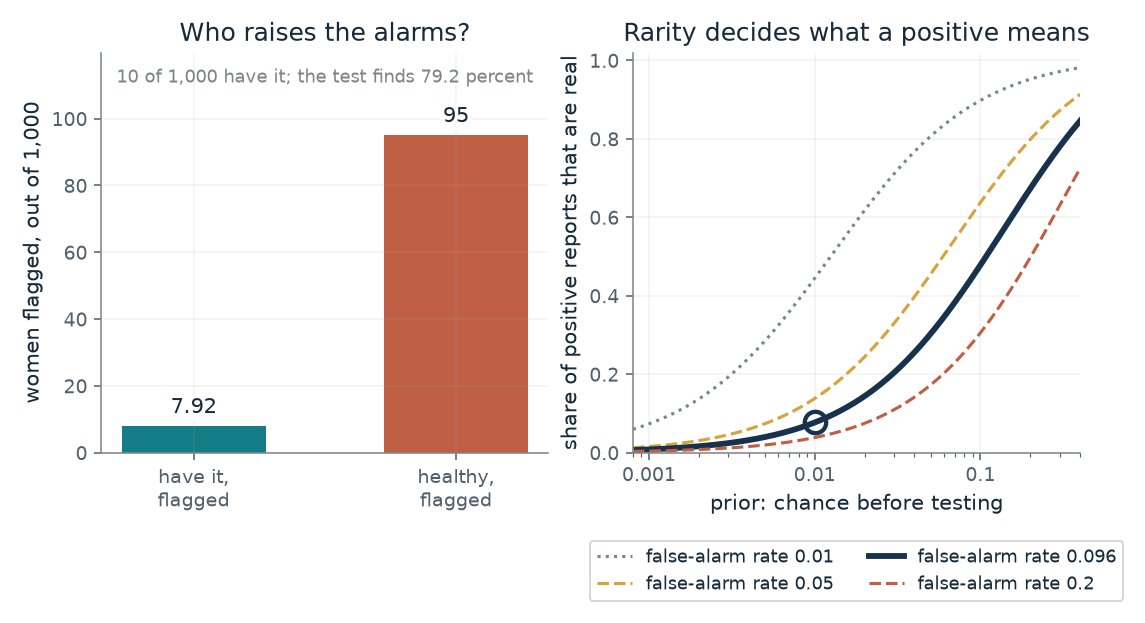

- **Real alarms per 1,000:** 7.92
- **False alarms per 1,000:** 95
- **Share of alarms that are real:** 7.69 percent
- **Test finds:** 79.2 percent

Of 1,000 women with a prior of 0.01, about 7.92 real cases and 95 healthy women are flagged. So 7.69 percent of positive reports are real, though the test finds 79.2 percent of cases.

Numerator H x prior = 0.792 x 0.01 = 0.00792. False-positive part F x (1 - prior) = 0.096 x 0.99 = 0.095. Share = 0.00792 / (0.00792 + 0.095) = 0.0769.

In [2]:
figure, values, explanation = bayes_picture(**{'prior': 0.01, 'false_alarm': 0.096})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why are most positive reports false when the test finds four cancers in five?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Prior: chance of the condition before testing = 0.01, False-alarm rate = 0.096: At a prior of 0.01 about 7.92 real cases and 95 healthy women are flagged, so about 7.7 percent of alarms are real. Move the prior to 0.1 with the same test and about 48 percent are real: only the prior moved.

**Takeaway:** A test's hit rate is not the chance a positive report is right; that depends on how rare the condition is and on the false-alarm rate.

**Why it matters:** Physicians in Eddy's sample put the answer near 75 percent, the hit rate, when it was near 8. Any alarm or detector, medical or not, needs the prior and the false-alarm rate before a positive result means much.

**In machines:** Any detector that raises an alarm behaves this way. A program can count the real and false alarms from the prior and the two rates, and recompute them when the population changes.

**Where it applies:** The rates describe the population the test is used on, and the prior is correct for that population. The result is an illustration of the calculation, not an individual clinical judgment.

**Check your understanding:** With the same test, suppose 1 woman in 10 has cancer (prior 0.1, false-alarm rate 0.096). What share of positive reports are real?

<details><summary>Show the answer</summary>

100 women have it and about 79.2 are flagged; of the 900 without, about 86.4 are flagged. The share is 79.2 / (79.2 + 86.4) = 0.478, close to half.

</details>

*Source: Chapter 15, Ten women with cancer, 990 without, and 103 alarms. Book formula with the numbers David Eddy posed in 1982 as the chapter reports them (prior 0.01, hit rate 0.792, false-alarm rate 0.096). The 1-in-10 prior is the chapter's own illustration, and the other values on the sliders are constructed. The counts per 1,000 are expected values, not a sample.*

## C15-D02: What does moving the cutoff change, and what does it leave alone?

If a yes depends on both how clear the evidence is and how readily the judge says yes, which of the two does a looser cutoff change?

Each heap counts how often each strength of evidence turns up. The area of the no-flash heap beyond the cutoff is the false-alarm rate, and the area of the flash heap beyond it is the hit rate. Sliding the cutoff changes both areas at once. Pushing the heaps apart (larger sharpness) is the only way to raise hits without raising false alarms.

$$
\text{hit}=\Phi(d'-c),\qquad \text{false alarm}=\Phi(-c),\qquad d'=z(\text{hit})-z(\text{false alarm})
$$

**Symbols:** d': sharpness of the evidence (d-prime): the gap between the heap centres, in units of the heap spread; c: the cutoff, measured from the centre of the no-flash heap in units of its spread; Phi: the area of the standard bell curve below a point; Phi(x) is the share of a heap below x; z: the inverse of Phi: the point with a given share of the heap below it

**Predict before looking:** Hold sharpness at 2.12. Predict what happens to the false-alarm rate when the cutoff moves from 1.3 to 2.0, and whether the hit rate falls by more or less.

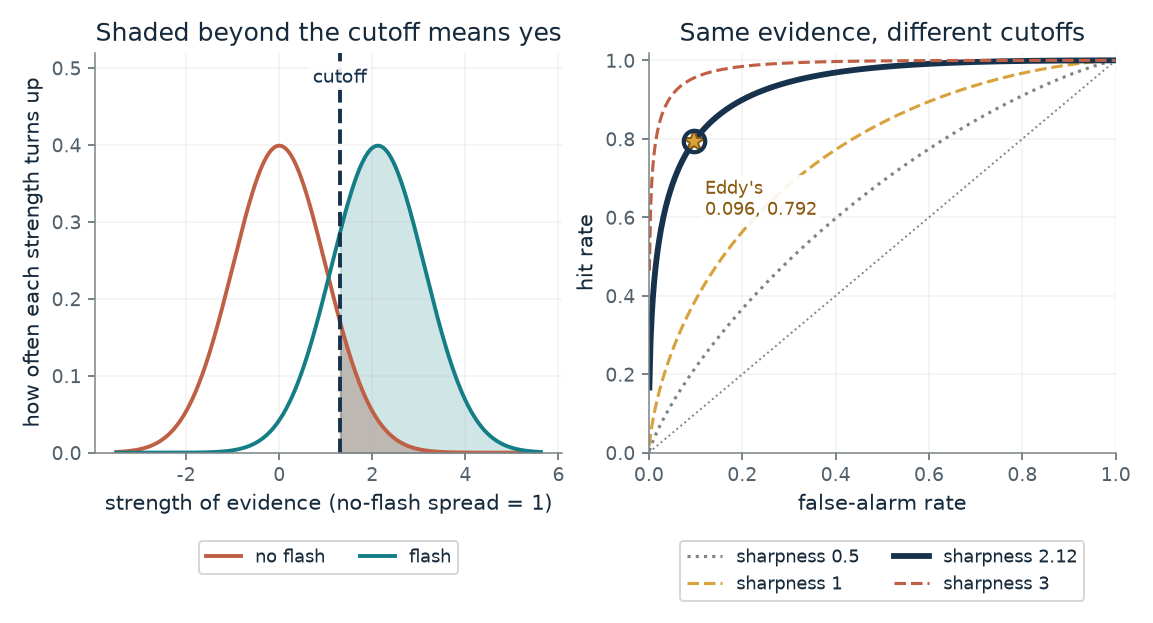

- **Hit rate:** 79.4 percent
- **False-alarm rate:** 9.68 percent
- **Real share of alarms at prior 0.01:** 7.65 percent
- **Sharpness (d-prime):** 2.12

With sharpness 2.12 and the cutoff 1.3 spreads above the no-flash centre, the hit rate is 79.4 percent and the false-alarm rate 9.68 percent. Move the cutoff and both rates move together; only a different sharpness changes the curve itself.

Hit = Phi(d' - c) = Phi(2.12 - 1.3) = 0.794. False alarm = Phi(-c) = Phi(-1.3) = 0.0968. At a prior of 0.01 the real share of alarms is 0.794 x 0.01 / (0.794 x 0.01 + 0.0968 x 0.99) = 0.0765. Sharpness 2.12 is the companion's reading of Eddy's two rates under equal-width normal heaps; the other sharpness values are constructed.

In [3]:
figure, values, explanation = detection_picture(**{'dprime': 2.12, 'cutoff': 1.3})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does moving the cutoff change, and what does it leave alone?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Sharpness of the evidence (d-prime) = 2.12, Cutoff (spreads above the no-flash centre) = 1.3: Sharpness 2.12 with the cutoff at 1.3 spreads gives a hit rate near 79.4 percent and a false-alarm rate near 9.7 percent, matching Eddy's 79.2 and 9.6 by construction: the sharpness was chosen from those two rates, so this is a reading of them, not a test. Slide the cutoff and the ringed point travels along the curve; only a different sharpness moves the curve.

**Takeaway:** A looser cutoff adds hits and false alarms together. Sharpness, the clarity of the evidence, stays put.

**Why it matters:** A stricter cutoff can cut false alarms but misses more cases, and no cutoff rescues evidence that is poor. Asking for the hit rate alone, or the false-alarm rate alone, hides the trade.

**In brains and behavior:** In Swets and colleagues' 1961 experiment, observers told that spots were common or rare said yes to blank trials 43 percent or 15 percent of the time, as if they moved a cutoff while seeing the same thing. Observers given payoffs moved their false-alarm rates in the expected direction, with one of three falling short of the authors' significance mark.

**In machines:** A classifier that outputs a score or a probability still needs a cutoff, and moving it trades hits against false alarms in just this way. The model here is a specification of that trade, not a claim about how any brain or test works.

**Where it applies:** Two normal evidence heaps of equal width. Outside that model the sharpness number can depend on the cutoff. Eddy's test is not known to behave like this, so the star is a reading, not a fact about the mammogram.

**Check your understanding:** At sharpness 2.12, move the cutoff from 1.3 to 2.0. What are the new hit and false-alarm rates?

<details><summary>Show the answer</summary>

Hit = Phi(2.12 - 2.0) = Phi(0.12), about 0.548. False alarm = Phi(-2.0), about 0.0228. Both fall: the judge is stricter, so it misses many more cases as well as raising fewer false alarms.

</details>

*Source: Chapter 15, Moving the cutoff buys hits and false alarms together. The chapter describes this model in words (two bell-shaped heaps of equal width, a cutoff, shaded areas) and gives no formulas, so the equation is the companion's statement of it. The sharpness 2.12 is computed here from Eddy's two rates under that model; Eddy did not frame his test this way, and the chapter says the framing is ours. The other sharpness values and the cutoffs are constructed. Swets and colleagues' false-alarm rates of 43 and 15 percent are quoted in the chapter and are not produced here.*

## C15-D03: Where should the cutoff go when a miss costs more than a false alarm?

A classifier gives a probability that a case is real. If a miss costs 9 times a false alarm, at what probability should it say yes?

Saying yes to a case that is real with chance p costs (1 - p) false alarms in expectation. Saying no costs p misses. The two costs are equal at p equal to C_fa over C_fa plus C_miss, and yes is cheaper above that. With equal costs that point is one half; with a miss costing 9 times as much it is 0.1.

$$
\text{say yes if } p>\frac{C_{\text{fa}}}{C_{\text{fa}}+C_{\text{miss}}},\qquad \text{cost(yes)}=(1-p)\,C_{\text{fa}},\quad \text{cost(no)}=p\,C_{\text{miss}}
$$

**Symbols:** p: the classifier's chance that the case is real; assumed calibrated; C_fa: cost of a false alarm (saying yes to a case that is not real), taken as 1; C_miss: cost of a miss (saying no to a real case), a multiple of C_fa

**Predict before looking:** If a miss costs 19 times a false alarm, predict the cutoff before moving the slider.

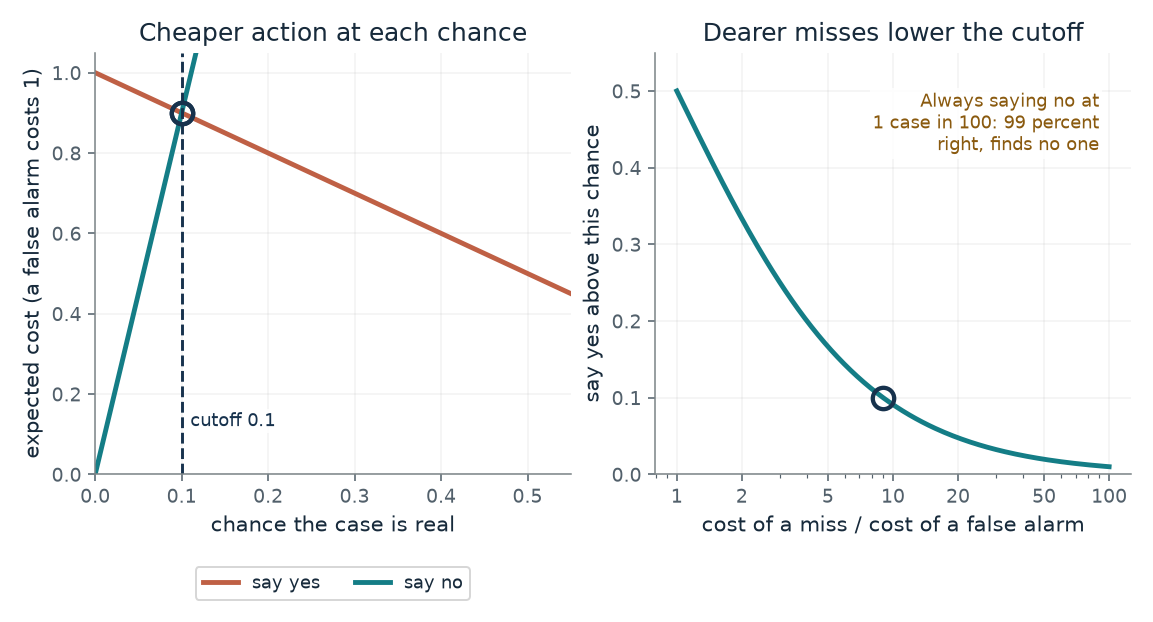

- **Say yes above chance:** 0.1
- **Cost of saying yes:** 0.9
- **Cost of saying no:** 0.9
- **Cheaper action:** equal cost (a tie)

With a miss costing 9 times a false alarm, the cheapest rule says yes above a chance of 0.1. At a chance of 0.1, saying yes costs 0.9 and saying no costs 0.9, so the cheaper action is: equal cost (a tie).

Cutoff = 1/(1 + 9) = 0.1. Saying yes costs (1 - 0.1) x 1 = 0.9. Saying no costs 0.1 x 9 = 0.9. This assumes the stated chance is trustworthy and a correct call costs nothing.

In [4]:
figure, values, explanation = cost_picture(**{'cost_ratio': 9, 'p': 0.1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Where should the cutoff go when a miss costs more than a false alarm?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Cost of a miss / cost of a false alarm = 9, Chance the case is real = 0.1: At a cost ratio of 9 the cutoff is 0.1, and at a chance of exactly 0.1 saying yes and saying no cost the same, 0.9 each. Anything above 0.1 favors yes.

**Takeaway:** The cheapest cutoff is set by the ratio of the two costs, not by accuracy, and it falls as misses get dearer.

**Why it matters:** A cutoff chosen for accuracy can be useless. When a condition affects 1 case in 100, a rule that always says no is right 99 percent of the time and finds no one. Software can compute the cutoff from stated costs and prevalence, and recheck it when either changes.

**In brains and behavior:** Swets and colleagues also changed what each answer paid, using a payoff matrix. Observers were told the odds and the pay, and their false-alarm rates moved the right way, though not to the authors' significance mark for one of three. Another four observers were told the best false-alarm rate for each session and followed it closely; the experiment did not show them working it out.

**In machines:** A program can compute the cutoff from the stated costs, which are a specification supplied by a person. The program does not supply the price of an error.

**Where it applies:** The stated probabilities are calibrated (when it says 70 percent it is right about 70 percent of the time), and a correct call costs nothing. Both costs are positive and supplied by a person.

**Check your understanding:** A miss costs 19 times a false alarm. Where is the cutoff, and what do yes and no cost at a chance of 0.1?

<details><summary>Show the answer</summary>

The cutoff is 1/(1 + 19) = 0.05. At 0.1, yes costs 0.9 and no costs 0.1 x 19 = 1.9, so yes is cheaper.

</details>

*Source: Chapter 15, Moving the cutoff buys hits and false alarms together. The chapter states two results: with equal costs and trustworthy probabilities, 0.5 is the cheapest cutoff, and with a miss costing 9 times a false alarm the rule says yes above 1 in 10. The expected-cost lines are the algebra behind them. The always-no rule at 1 case in 100 is the chapter's example. The costs on the slider are constructed.*

## C15-D04: How does a noisy running total decide when to stop?

If evidence drifts toward an answer with random jitter, when does it reach the bound, and how often does it reach the wrong one?

Each flicker of evidence is a hint that might point the wrong way. The total grows only on average, at the drift, and jitters around that line. A stronger drift reaches the bound sooner, as in the figure on the right. Single trials scatter around the noise-free time, and a few reach the wrong edge.

$$
dX_t=v\,dt+\sigma\,dW_t,\ \text{stop at }\pm a;\qquad \text{noise-free time}=\frac{a}{v}
$$

**Symbols:** X_t: the evidence total at time t, starting at zero; v: the drift: the average gain per second; sigma: the noise: the size of the random ups and downs; a: the bound: the plus edge is one answer and the minus edge the other

**Predict before looking:** With drift 2 and bound 10, predict what raising the noise from 0 to 8 does to the average decision time, and to the chance of the wrong edge.

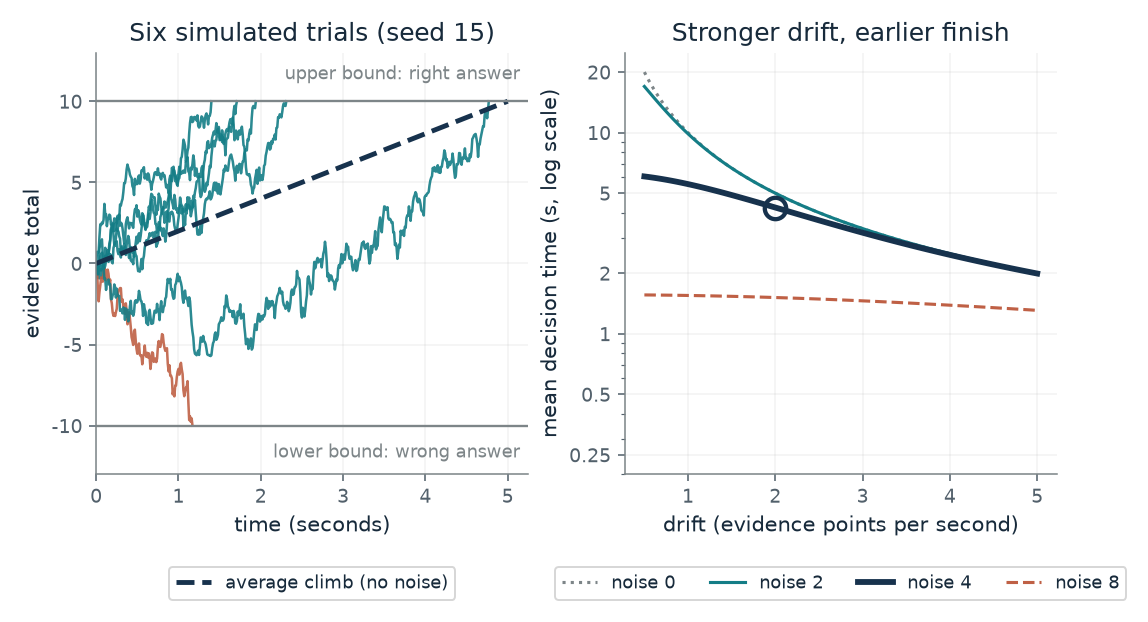

- **Time with no noise (s):** 5
- **Mean decision time with noise (s):** 4.24
- **Chance of the wrong edge:** 7.59 percent
- **Drawn trials that hit the upper edge:** 5 of 6

With drift 2, noise 4 and bound 10, the noise-free climb takes 5 s. The six drawn trials stopped between 1.17 and 4.77 s. The exact mean over all trials is 4.24 s, with a 7.59 percent chance of ending at the wrong edge.

Noise-free time = a/v = 10/2 = 5 s. Mean time with noise = (a/v) tanh(a v / sigma^2) = 5 x tanh(10 x 2 / 4^2) = 4.24 s. Chance of the wrong edge = 1/(1 + exp(2 a v / sigma^2)) = 0.0759.

In [5]:
figure, values, explanation = diffusion_picture(**{'drift': 2, 'noise': 4, 'bound': 10})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does a noisy running total decide when to stop?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Drift (evidence points per second) = 2, Noise (size of the random nudges) = 0, Bound = 10: With no noise the total climbs straight to the bound in 5 seconds, as in the chapter. Now raise the noise: the mean time barely moves at noise 2, falls to about 4.2 s at noise 4 and about 1.5 s at noise 8, but the chance of ending at the wrong edge rises to about 35 percent.

**Takeaway:** In this model, drift sets the average climb, noise scatters single trials, and with the bound fixed, more noise gives faster answers and more wrong ones.

**Why it matters:** A bound turns accumulated evidence into a decision. Where the bound sits, and how much noise the evidence carries, set both the wait and the error rate, which is why who sets the bound matters.

**In brains and behavior:** In 2002 two monkeys judged moving dots, and the firing of 54 cells in a parietal area climbed faster when more dots drifted together and reached about 69 spikes per second before the eye moved. These are correlations in two monkeys. Nothing was silenced, and the 2002 paper did not write down a diffusion model.

**In machines:** A diffusion model is a theory fitted to summarize data, not a machine and not a finding that the cells compute a bound. Under a suitable evidence model and scaling it shares a running sum with Wald's test, as Bogacz and colleagues showed in 2006.

**Where it applies:** A positive drift, a start at zero between two symmetric bounds, and noise that is steady over time. Noise zero is the noise-free limit, with no wrong edge.

**Check your understanding:** With no noise and bound 10, how long does a drift of 4 take, and what does that suggest about doubling the drift from 2?

<details><summary>Show the answer</summary>

10 / 4 = 2.5 seconds, half of the 5 seconds at drift 2. Doubling the drift halves the noise-free time.

</details>

*Source: Chapter 15, Parietal cells in two monkeys climbed to one firing rate. Book equation and its worked example (drift 2 points a second, bound 10, no noise: 5 seconds; doubling the drift halves it). The mean decision time (a/v) tanh(a v / sigma^2) and the wrong-edge chance 1/(1 + exp(2 a v / sigma^2)) are standard closed forms for this model that the chapter does not state; they are the companion's addition and the tests check them against a fine-step simulation. The six drawn paths are one simulation with seed 15, not a recording. The chapter's 409 ms and 824 ms reaction times are reported results that this model does not produce.*

## C15-D05: Can stopping at a lead beat counting a fixed number of votes?

Judges vote one at a time. Does stopping when one answer leads by three beat taking nine votes and counting them?

The lead is a running total that moves up one vote for one answer and down one for the other, so reaching a lead of L is a random walk hitting a bound. When judges are better than chance the walk reaches the right bound more often, and it reaches either bound quickly when each vote is nearly certain. A fixed count must plan for the worst case and so spends the same votes on easy cases as on hard ones.

$$
P_{\text{right}}=\frac{1}{1+\left(\frac{1-q}{q}\right)^{L}},\qquad E[\text{votes}]=\frac{L\,(2P_{\text{right}}-1)}{2q-1}
$$

**Symbols:** q: the chance each judge is right, the same for every vote and independent; L: the lead at which voting stops, the bound; P_right: the chance the lead rule ends on the right answer; E[votes]: the average number of votes asked; L squared when q is one half

**Predict before looking:** At q = 0.7, predict whether the lead-3 rule uses more or fewer votes than nine on average, and whether it is more or less accurate than the nine-vote count.

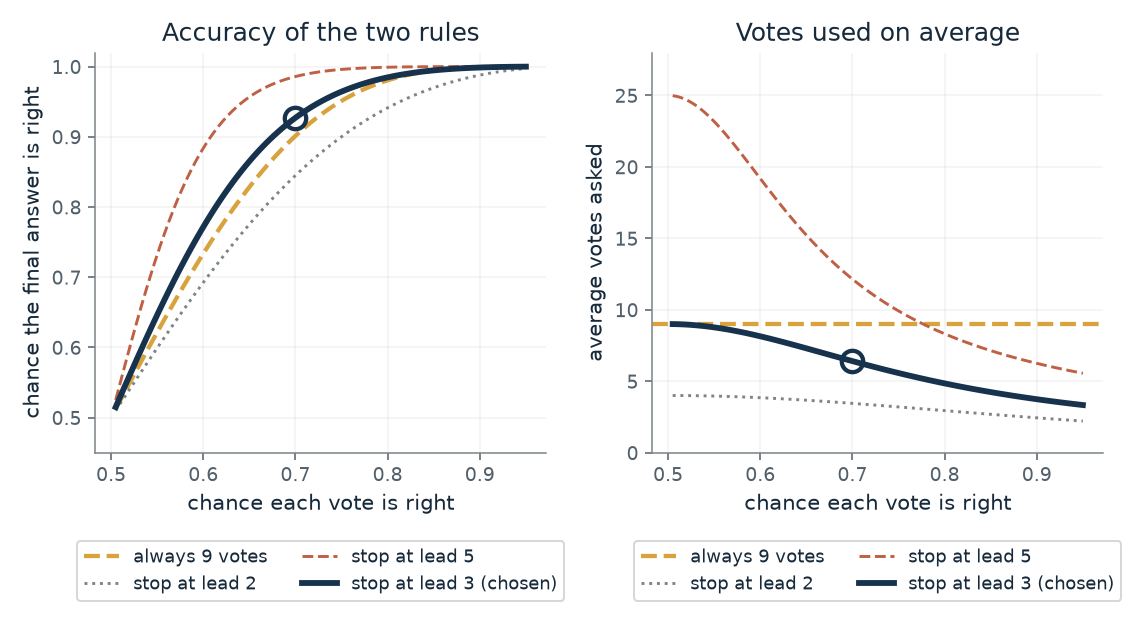

- **Lead rule: chance right:** 92.7 percent
- **Always 9 votes: chance right:** 90.1 percent
- **Lead rule: average votes:** 6.41
- **Fixed votes needed to match the lead rule:** 13

Judges who are each right with chance 0.7 give a lead-3 rule a 92.7 percent chance of ending right, using 6.41 votes on average. A fixed count needs 13 votes to reach that accuracy; always 9 gives 90.1 percent.

Lead rule: chance right = 1/(1 + ((1 - q)/q)^L) = 1/(1 + (0.3/0.7)^3) = 0.927. Average votes = L (2P - 1)/(2q - 1) = 3 x 0.854 / 0.4 = 6.41. Fixed 9: chance of at least 5 right votes = 0.901.

In [6]:
figure, values, explanation = lead_picture(**{'accuracy': 0.7, 'lead': 3})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can stopping at a lead beat counting a fixed number of votes?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Chance each vote is right (q) = 0.7, Lead at which voting stops (L) = 3: At q = 0.7 the lead-3 rule is right 92.7 percent of the time and asks 6.41 votes on average. Always taking 9 votes is right 90.1 percent of the time, and a fixed count needs 13 votes to match the lead rule, about twice the average.

**Takeaway:** Stopping when the evidence is lopsided can match a larger fixed count with about half the votes on average, but the saving is an average, not a promise on every run.

**Why it matters:** A rule that asks again only when the tally is close spends effort where the answer is unsettled. Wald's test is the idea in full; the saving is on average, and a fixed test is better when the number of observations is set in advance for some other reason.

**In brains and behavior:** In the 2002 study reaction times for choices toward the cell's target lengthened as evidence weakened, 409 milliseconds when half the dots drifted together and 824 when none did. A fixed-bound diffusion model predicts that general pattern. This demonstration does not produce those times, and Wald's test has not been shown in a brain.

**In machines:** A system that asks again only when its tally is close is following a lead rule. The lead is a bound that a person or developer chooses.

**Where it applies:** Independent judges with one known accuracy above one half, the same for either answer, and a fixed-count rule that takes an odd number of votes. Wald's optimality proof covers two simple hypotheses with independent, identically distributed observations; this toy has that form but is only an illustration of the idea.

**Check your understanding:** At q = 0.9 and a lead of 3, what is the chance of ending right and the average votes, and how does nine fixed votes compare?

<details><summary>Show the answer</summary>

P = 1/(1 + (0.1/0.9)^3) = 0.9986, votes = 3 x (2 x 0.9986 - 1)/0.8 = 3.74. Nine fixed votes are right 0.9991 of the time, so the lead rule is almost as accurate with about 3.74 votes against 9.

</details>

*Source: Chapter 15, Wald's wartime test, and a bound that depends on the price of time. The chapter describes the vote game in words (nine votes counted, against stopping once one answer is three ahead) and gives no accuracies. The numbers here are the companion's exact calculation for that game, using the random-walk formulas, checked in the tests against exact enumeration and a seeded simulation. It is the chapter's simplified version, not Wald's full test. Wald's 'about 50%' saving is quoted from the chapter and is a statement about his test, not about this toy.*

## C15-D06: How does the price of time change the best bound?

A careful setting and a quick setting each earn correct answers. Which earns more per second, and does it depend on the delay between trials?

Each cycle costs the decision time, the fixed time, the delay and, after an error, the time-out. The numerator counts only correct answers. With a short delay, the seconds spent deciding dominate, so the quick setting wins despite its errors. With a long delay, the decision time is a small slice and the extra errors cost more than the seconds saved, so the careful setting wins.

$$
\mathrm{RR}=\frac{1-\mathrm{ER}}{\mathrm{DT}+T_{nd}+D+\mathrm{ER}\cdot D_p}
$$

**Symbols:** RR: reward rate: correct answers per second over the whole cycle; ER: error rate, the chance of answering wrongly; DT: average decision time, seconds spent gathering evidence; T_nd: non-decision time, a fixed part of each trial (0.3 s here); D, D_p: delay between trials, and the extra time-out after an error

**Predict before looking:** With no time-out, predict whether the careful setting wins at a 2 second delay, at a 6 second delay, or at both.

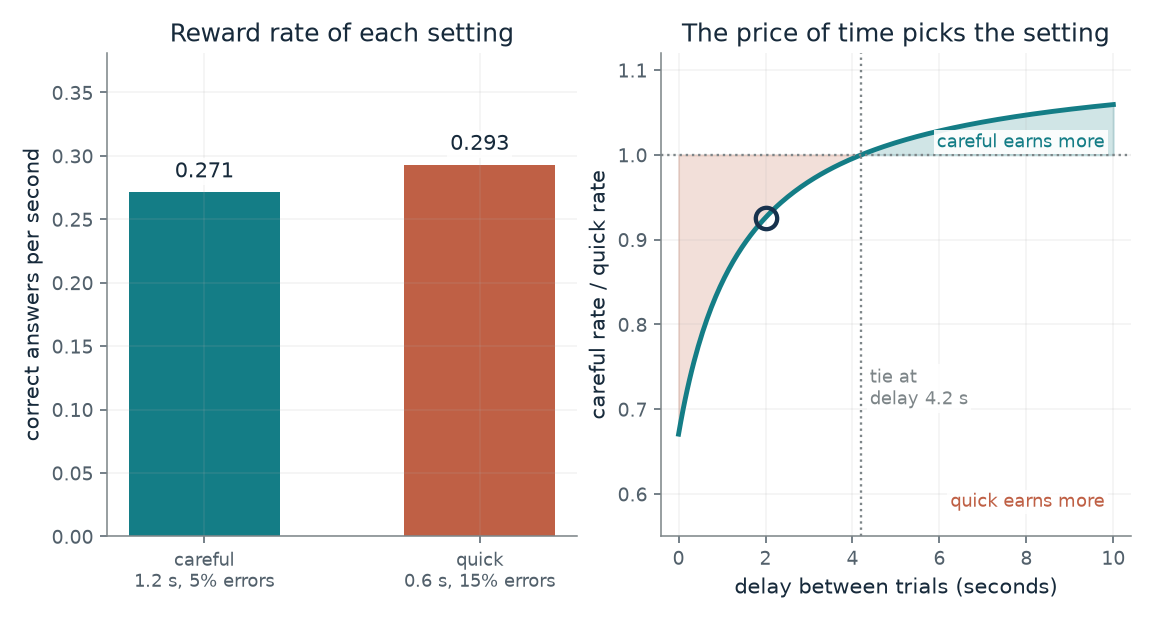

- **Careful: correct per second:** 0.271
- **Quick: correct per second:** 0.293
- **Earns more:** quick
- **Delay where they tie:** 4.2 s

With a 2 s delay between trials and a 0 s time-out after errors, careful earns 0.271 correct answers a second and quick 0.293, so quick earns more. The two settings tie at a delay of 4.2 s.

Careful: (1 - 0.05) / (1.2 + 0.3 + 2 + 0.05 x 0) = 0.271. Quick: (1 - 0.15) / (0.6 + 0.3 + 2 + 0.15 x 0) = 0.293.

In [7]:
figure, values, explanation = reward_picture(**{'delay': 2, 'timeout': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does the price of time change the best bound?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Delay between trials (seconds) = 6, Extra time-out after an error (seconds) = 0: At a 6 second delay careful earns about 0.127 correct answers a second and quick about 0.123, so careful wins. At 2 seconds quick wins, 0.293 against 0.271, and the two tie at a delay of 4.2 seconds.

**Takeaway:** A long delay makes the seconds spent deciding a small part of each cycle, while errors cost the same, so the best bound depends on the price of time.

**Why it matters:** A bound is not good or bad on its own. Whoever sets the costs of error and of delay sets the best bound, and the reward rate is one way to put those costs on one scale.

**In brains and behavior:** Hanks and colleagues rewarded speed in two monkeys. A model of their behavior needed the evidence to travel less far to the bound under speed, while the firing rate reached just before the eye moved was similar in both regimes. The recordings do not establish that those cells generated the control signal.

**In machines:** A system that can compute a reward rate from stated times and errors can re-pick its bound when the delay changes. The costs are supplied by a person.

**Where it applies:** Fixed average decision times and error rates for each setting, independent trials, and a long-run average. The Hanks paper never computed a reward rate or tested whether the monkeys maximized it, and fast guessing cannot be ruled out.

**Check your understanding:** With no time-out and a 2 second delay, what do careful and quick earn per second?

<details><summary>Show the answer</summary>

Careful: 0.95 / (1.2 + 0.3 + 2) = 0.95/3.5 = 0.271. Quick: 0.85 / (0.6 + 0.3 + 2) = 0.85/2.9 = 0.293, so quick earns more.

</details>

*Source: Chapter 15, Wald's wartime test, and a bound that depends on the price of time. Book formula (Gold and Shadlen's, as set out by Bogacz and colleagues in 2006) and the chapter's constructed example: careful 1.2 s with 5 percent errors, quick 0.6 s with 15 percent, 0.3 s fixed time, delays of 2 and 6 seconds. The tie delay and the time-out values are the companion's algebra on that example. Nothing here is a measured reward rate.*

## C15-D07: When does a sampler stop, and does a settled tally mean it is right?

A language model is asked one question again and again. How many samples does a settle-and-stop rule draw, and how often does the final answer end up wrong?

After each sample the rule asks how settled the two leading counts look. Four agreeing samples in a row are enough at 0.95, since 31/32 is above 0.95 and 15/16 is not. When the likelier answer shows up only a little more often than the other, the counts wander and the estimate rarely passes the threshold, so the sampler runs to the cap or sometimes settles on the wrong leader.

$$
\text{estimate}=P\!\left(\mathrm{Bin}(a+b+1,\tfrac12)\le a\right),\qquad \text{stop if estimate}>0.95\ \text{or samples}=40
$$

**Symbols:** a, b: the counts so far for the leading answer and the runner-up; estimate: how likely the leader's underlying probability exceeds the runner-up's; not the chance the leader is true; s: the chance that one sample gives the truly likelier of the two answers

**Predict before looking:** Predict how many samples the rule needs on average when the likelier answer shows up 60 percent of the time, and how often it never settles within 40.

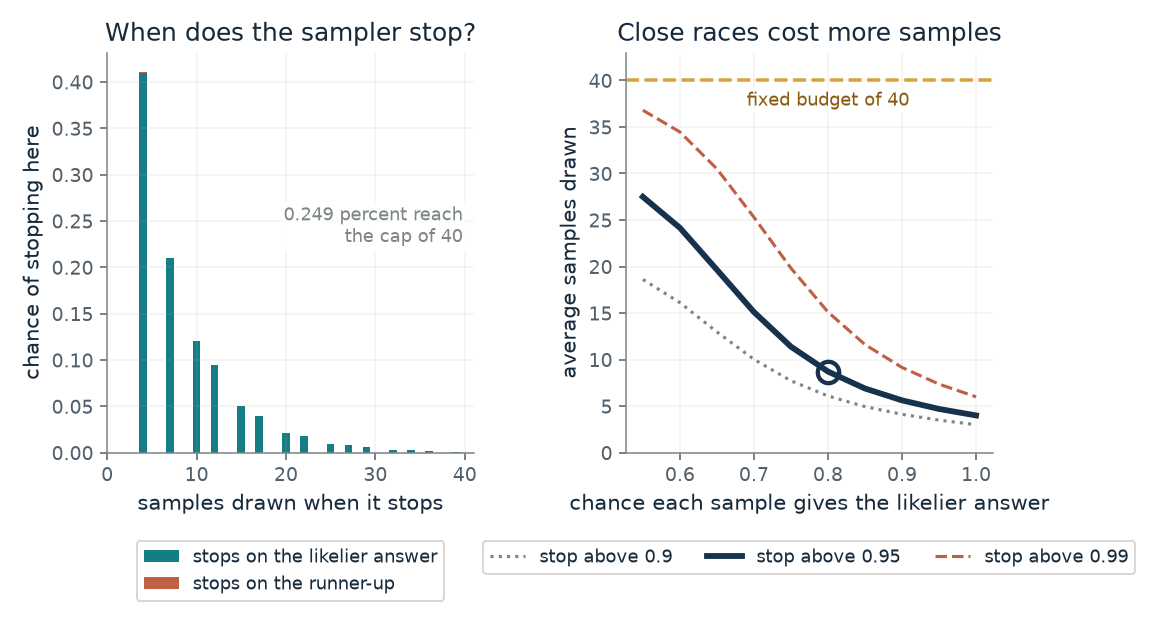

- **Average samples drawn:** 8.72
- **Chance it stops on the runner-up before the cap:** 0.186 percent
- **Chance it hits the cap:** 0.249 percent
- **Chance of a wrong final answer, cap included:** 0.187 percent

When 80 percent of samples give the likelier answer and the sampler stops above 0.95, it draws 8.72 samples on average against a fixed 40. It stops on the runner-up 0.186 percent of the time, and the final answer is wrong 0.187 percent of the time if capped runs return their leader. Settled means stable, not true.

Estimate = P(Bin(a + b + 1, 1/2) <= a) for the leader's count a. Four unbroken matches give P(Bin(5, 1/2) <= 4) = 31/32 = 0.969. At threshold 0.95 the earliest stop is after 4 samples. The exact tally is a sum over all (a, b) counts, not a simulation. The estimate is the companion's reading of the chapter's description. Wrong if a capped run returns its leader = stops on the runner-up 0.186 percent + capped with the runner-up ahead 0.000367 percent = 0.187 percent; 0.00127 percent of runs reach the cap tied and have no leader. That cap rule is the companion's assumption; the chapter suggests handing an unsettled case to a person.

In [8]:
figure, values, explanation = sampler_picture(**{'share': 0.8, 'threshold': 0.95})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='When does a sampler stop, and does a settled tally mean it is right?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Chance a sample gives the likelier answer (s) = 0.6, Stopping threshold = 0.95: At s = 0.6 the sampler draws 24.2 samples on average, about 38 percent of runs hit the cap of 40 without settling, and about 5 percent stop on the runner-up. If a capped run returned its current leader (the companion's assumption, not the chapter's), about 10 percent of final answers would be wrong once those capped runs are counted. At s = 0.8 it needs 8.7 samples on average.

**Takeaway:** A close race costs many samples, and a tally that settles is stable, not necessarily true.

**Why it matters:** Where a tally never settles before the cap, a system could hand the question to a person. And ten answers based on the same mistaken source repeat the mistake rather than add independent evidence.

**In brains and behavior:** No study here compares a brain result with a machine result. The monkeys and the sampler both stop a tally once it looks settled, but the sampler's bound came from its developers.

**In machines:** Adaptive-Consistency stops on an estimated probability of stability, not on a fixed lead, so it is related to Wald's test and not an instance of it. The authors say it is anticipated to fail where self-consistency fails.

**Where it applies:** Independent samples, two answers, and a fixed chance s that each sample gives the likelier one. Real samples from one model can share a source of error, which this model leaves out.

**Check your understanding:** At a threshold of 0.95, how many unbroken matching samples does the rule need before it stops?

<details><summary>Show the answer</summary>

Four. Three give P(Bin(4, 1/2) <= 3) = 15/16 = 0.9375, below 0.95. Four give P(Bin(5, 1/2) <= 4) = 31/32 = 0.969, above it.

</details>

*Source: Chapter 15, A language model sampled until its answers settled. The chapter describes the method (stop once the estimate passes 0.95, or at 40 samples on reasoning tasks, both chosen by the developers) but not the formula. The estimate here is the companion's reading, a uniform-prior Beta(a+1, b+1) mass above one half, which equals the binomial sum shown. Only the two leading answers are modeled, and the tally is computed exactly, not simulated. The chapter's 3.3 times fewer samples and 0.04 point accuracy drop are results reported by Aggarwal and colleagues on 17 datasets, and are not reproduced here.*

## Bring it to your own question

Ask for the prior (how common the event is where the test is used), the hit and false-alarm rates for that population, the cost of each kind of error and the price of waiting. Then choose the matching card: Bayes' rule for what a positive report means, the cost cutoff for where to draw the line, a lead rule or a bound for how long to keep collecting evidence, the reward rate for how the price of time moves the bound. Report the answer, the assumption it depends on, and who supplied the costs.

Use the `mmi-ch15-when-to-decide` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.